# Palo Alto Networks (PANW) — Future Performance Analysis
COMP0164 Digital Finance group coursework. Data: Yahoo Finance via `yfinance` (split-adjusted prices).

In [77]:
# ==== 1. Setup & parameters ====
import os
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (10, 5.5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
})

TARGET = "PANW"
PEERS = ["CRWD", "FTNT", "ZS"]
MARKET = "^GSPC"
TICKERS = [TARGET] + PEERS + [MARKET]
LABELS = {"PANW": "Palo Alto Networks", "CRWD": "CrowdStrike",
          "FTNT": "Fortinet", "ZS": "Zscaler", "^GSPC": "S&P 500"}

START = "2021-11-26"        # 5-year window
END = "2026-11-26"          # exclusive -> last trading day is 25 Nov 2026 (26 Nov = US Thanksgiving)
REFRESH_DATA = False        # True = download fresh data from Yahoo; False = reuse the saved snapshot in data/
RISK_FREE = 0.042           # 3-month US Treasury yield, Nov 2026 (FRED, DGS3MO)
EQUITY_RISK_PREMIUM = 0.042 # Damodaran implied ERP, 1 Oct 2026
SEED = 42                   # makes Monte Carlo results reproducible

os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)
os.makedirs("tables", exist_ok=True)

def save(fig, name):
    """Save a figure as a high-resolution PNG for the report."""
    fig.savefig(f"figures/{name}.png", dpi=300, bbox_inches="tight")

def show(df, pct=(), dec2=(), dec1=(), money=()):
    """Return a formatted copy of a table for display (keeps the raw numbers untouched)."""
    out = df.copy().astype(object)
    for cols, f in [(pct, "{:.1%}"), (dec2, "{:.2f}"), (dec1, "{:.1f}"), (money, "${:,.2f}")]:
        for c in cols:
            out[c] = df[c].map(lambda v: f.format(v) if pd.notna(v) else "n/a")
    return out

In [78]:
# ==== 2. Download prices ====
PRICES_FILE = "data/prices_snapshot.csv"

if REFRESH_DATA or not os.path.exists(PRICES_FILE):
    raw = yf.download(TICKERS, start=START, end=END, auto_adjust=True, progress=False)
    prices = raw["Close"][TICKERS].dropna()
    prices.to_csv(PRICES_FILE)
    print("Downloaded fresh prices from Yahoo Finance and saved snapshot.")
else:
    prices = pd.read_csv(PRICES_FILE, index_col=0, parse_dates=True)[TICKERS]
    print("Loaded saved price snapshot (set REFRESH_DATA = True to re-download).")

print(f"Period: {prices.index[0].date()} to {prices.index[-1].date()} ({len(prices)} trading days)")
prices.to_csv("tables/prices.csv")
prices.tail()

Loaded saved price snapshot (set REFRESH_DATA = True to re-download).
Period: 2021-11-26 to 2026-11-25 (1255 trading days)


,PANW,CRWD,FTNT,ZS,^GSPC
Date,,,,,
2026-11-19,361.730011,243.460007,131.460007,205.710007,7175.830078
2026-11-20,343.320007,229.440002,124.559998,194.820007,6910.390137
2026-11-23,353.429993,208.970001,131.100006,229.240005,7237.169922
2026-11-24,352.989990,210.860001,132.500000,231.619995,7201.089844
2026-11-25,356.140015,209.300003,134.960007,230.860001,7182.779785


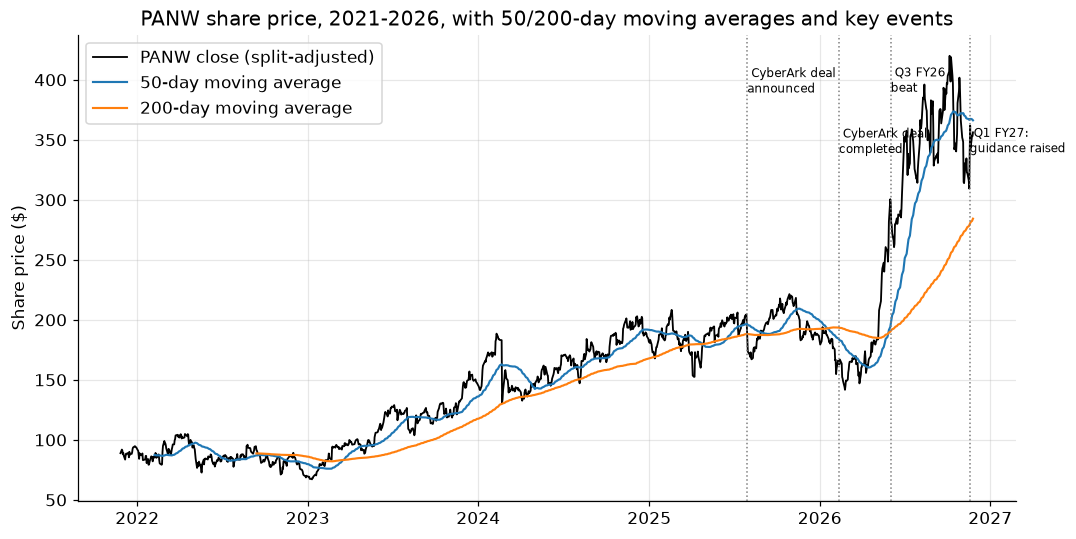

Latest close $356.14 | 50-day MA $366.18 | 200-day MA $284.24
Trend signal: price below at least one MA


In [79]:
# ==== 2b. PANW price history with moving averages and key events ====
# Event dates are taken from company press releases; add or edit as needed
EVENTS = {
    "2025-07-30": "CyberArk deal\nannounced",
    "2026-02-11": "CyberArk deal\ncompleted",
    "2026-06-02": "Q3 FY26\nbeat",
    "2026-11-18": "Q1 FY27:\nguidance raised",
}
px = prices[TARGET]
ma50, ma200 = px.rolling(50).mean(), px.rolling(200).mean()

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(px.index, px, color="black", linewidth=1.2, label="PANW close (split-adjusted)")
ax.plot(ma50.index, ma50, color="tab:blue", linewidth=1.4, label="50-day moving average")
ax.plot(ma200.index, ma200, color="tab:orange", linewidth=1.4, label="200-day moving average")
y_lo, y_rng = px.min(), px.max() - px.min()
for i, (date, label) in enumerate(EVENTS.items()):
    d = pd.Timestamp(date)
    if px.index[0] <= d <= px.index[-1]:
        ax.axvline(d, color="grey", linestyle=":", linewidth=1)
        last = i == len(EVENTS) - 1   # put the last label left of its line so it stays inside the chart
        ax.text(d, y_lo + y_rng * (0.02 + 0.13 * (i % 2)), (label + " ") if last else (" " + label),
                fontsize=8, va="bottom", ha="right" if last else "left",
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1))
ax.set_title("PANW share price, 2021-2026, with 50/200-day moving averages and key events")
ax.set_ylabel("Share price ($)")
ax.legend(loc="upper left")
save(fig, "09_price_history_events")
plt.show()

print(f"Latest close ${px.iloc[-1]:,.2f} | 50-day MA ${ma50.iloc[-1]:,.2f} | 200-day MA ${ma200.iloc[-1]:,.2f}")
print("Trend signal:", "price above both MAs (bullish)" if px.iloc[-1] > max(ma50.iloc[-1], ma200.iloc[-1])
      else "price below at least one MA")

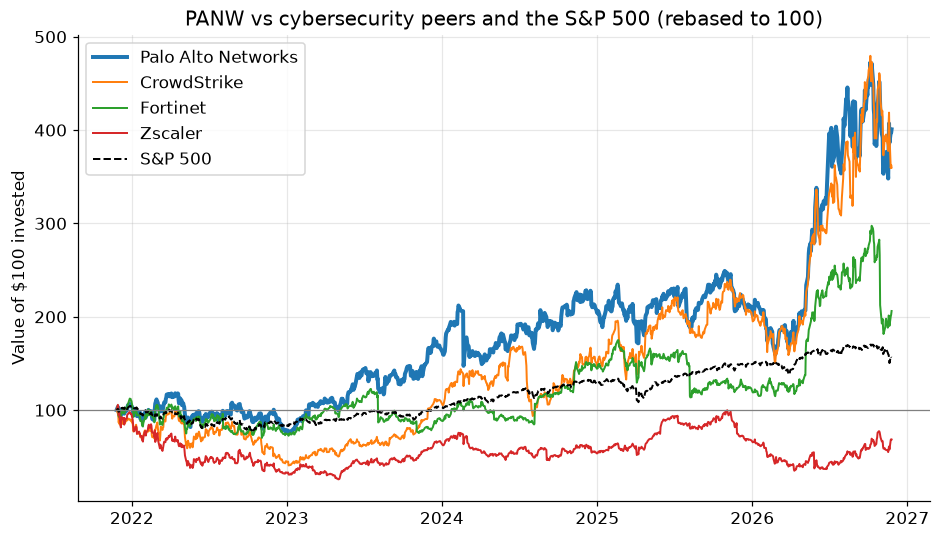

In [80]:
# ==== 3. Relative performance vs peers and the market ====
rebased = prices / prices.iloc[0] * 100

fig, ax = plt.subplots()
for t in TICKERS:
    ax.plot(rebased.index, rebased[t], label=LABELS[t],
            linewidth=2.6 if t == TARGET else 1.3,
            linestyle="--" if t == MARKET else "-",
            color="black" if t == MARKET else None)
ax.axhline(100, color="grey", linewidth=0.8)
ax.set_title("PANW vs cybersecurity peers and the S&P 500 (rebased to 100)")
ax.set_ylabel("Value of $100 invested")
ax.legend()
save(fig, "01_relative_performance")
plt.show()

In [81]:
# ==== 4. Risk & return metrics ====
daily = prices.pct_change().dropna()
years = (prices.index[-1] - prices.index[0]).days / 365.25

metrics = pd.DataFrame(index=TICKERS)
metrics["Total return"] = prices.iloc[-1] / prices.iloc[0] - 1
metrics["CAGR"] = (prices.iloc[-1] / prices.iloc[0]) ** (1 / years) - 1
metrics["Ann. volatility"] = daily.std() * np.sqrt(252)
metrics["Sharpe ratio"] = (daily.mean() * 252 - RISK_FREE) / metrics["Ann. volatility"]
metrics["Max drawdown"] = (prices / prices.cummax() - 1).min()

# Beta: 2 years of weekly returns vs the S&P 500 (same convention as Bloomberg's default BETA)
weekly = prices.resample("W-FRI").last().pct_change().dropna()
weekly = weekly[weekly.index >= weekly.index[-1] - pd.DateOffset(years=2)]
metrics["Beta (2y weekly)"] = weekly.cov()[MARKET] / weekly[MARKET].var()

# CAPM: required return = rf + beta * market risk premium
metrics["CAPM expected return"] = RISK_FREE + metrics["Beta (2y weekly)"] * EQUITY_RISK_PREMIUM

metrics.index = [LABELS[t] for t in metrics.index]
metrics.to_csv("tables/risk_return_metrics.csv")
show(metrics,
     pct=["Total return", "CAGR", "Ann. volatility", "Max drawdown", "CAPM expected return"],
     dec2=["Sharpe ratio", "Beta (2y weekly)"])

,Total return,CAGR,Ann. volatility,Sharpe ratio,Max drawdown,Beta (2y weekly),CAPM expected return
Palo Alto Networks,300.7%,32.0%,44.2%,0.76,-36.0%,1.21,9.3%
CrowdStrike,259.9%,29.2%,53.0%,0.67,-60.5%,1.35,9.9%
Fortinet,106.1%,15.6%,46.1%,0.46,-39.0%,1.22,9.3%
Zscaler,-31.5%,-7.3%,58.8%,0.10,-75.6%,1.13,9.0%
S&P 500,56.3%,9.4%,17.4%,0.36,-25.4%,1.00,8.4%


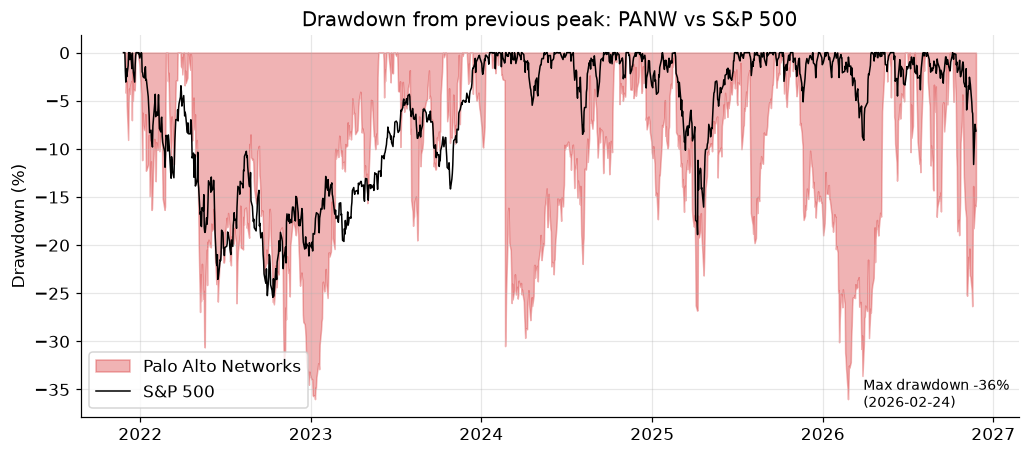

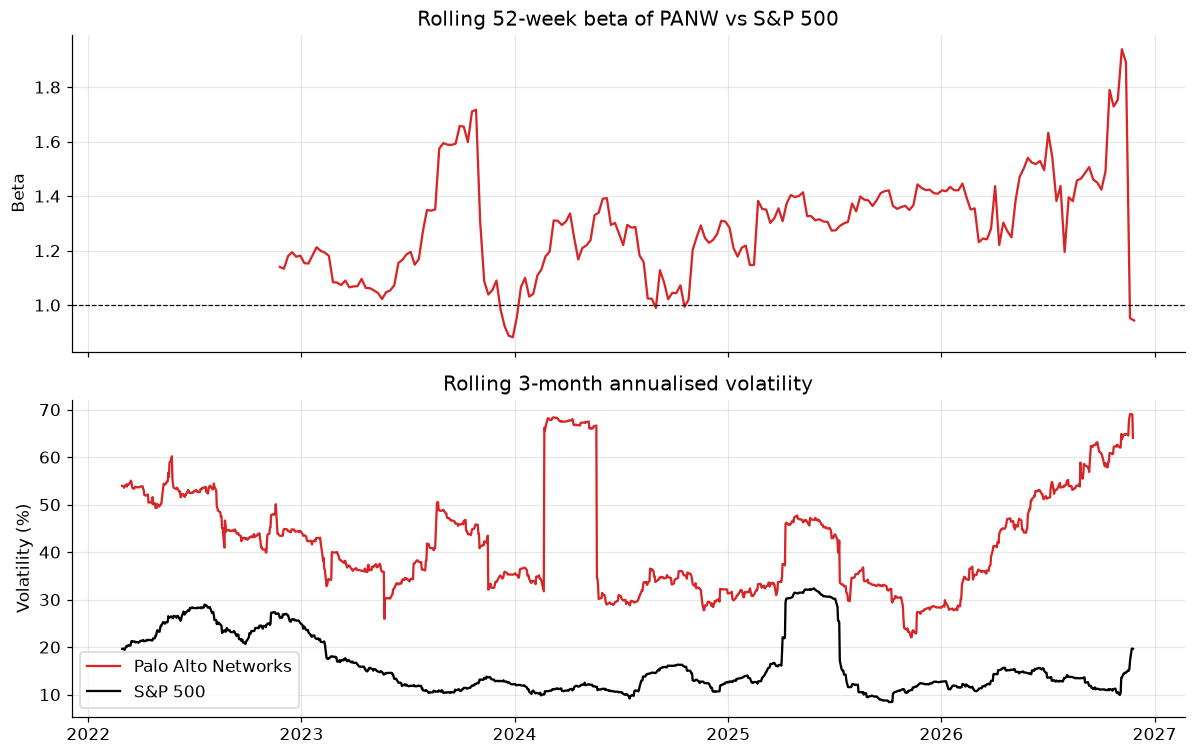

Beta range (52-week rolling): 0.88 to 1.94, latest 0.94
PANW 3-month volatility: latest 64.0%, 5-year average 42.2%


In [82]:
# ==== 4b. Drawdowns and time-varying risk (rolling beta & volatility) ====
dd = prices[[TARGET, MARKET]] / prices[[TARGET, MARKET]].cummax() - 1
trough = dd[TARGET].idxmin()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.fill_between(dd.index, dd[TARGET] * 100, 0, color="tab:red", alpha=0.35, label=LABELS[TARGET])
ax.plot(dd.index, dd[MARKET] * 100, color="black", linewidth=1, label=LABELS[MARKET])
ax.annotate(f"Max drawdown {dd[TARGET].min():.0%}\n({trough.date()})", xy=(trough, dd[TARGET].min() * 100),
            xytext=(10, -5), textcoords="offset points", fontsize=9)
ax.set_title("Drawdown from previous peak: PANW vs S&P 500")
ax.set_ylabel("Drawdown (%)")
ax.legend(loc="lower left")
save(fig, "10_drawdowns")
plt.show()

weekly_all = prices.resample("W-FRI").last().pct_change().dropna()
roll_beta = weekly_all[TARGET].rolling(52).cov(weekly_all[MARKET]) / weekly_all[MARKET].rolling(52).var()
roll_vol = daily[[TARGET, MARKET]].rolling(63).std() * np.sqrt(252)

fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
a1.plot(roll_beta.index, roll_beta, color="tab:red")
a1.axhline(1, color="black", linewidth=0.8, linestyle="--")
a1.set_title("Rolling 52-week beta of PANW vs S&P 500")
a1.set_ylabel("Beta")
for t, c in [(TARGET, "tab:red"), (MARKET, "black")]:
    a2.plot(roll_vol.index, roll_vol[t] * 100, color=c, label=LABELS[t])
a2.set_title("Rolling 3-month annualised volatility")
a2.set_ylabel("Volatility (%)")
a2.legend()
fig.tight_layout()
save(fig, "11_rolling_beta_volatility")
plt.show()

print(f"Beta range (52-week rolling): {roll_beta.min():.2f} to {roll_beta.max():.2f}, latest {roll_beta.iloc[-1]:.2f}")
print(f"PANW 3-month volatility: latest {roll_vol[TARGET].iloc[-1]:.1%}, 5-year average {roll_vol[TARGET].mean():.1%}")

## Macroeconomic analysis
US 10-year Treasury yield (`DGS10`) and the trade-weighted US dollar index (`DTWEXBGS`) from FRED (Federal Reserve Bank of St. Louis).
High-multiple growth stocks are sensitive to interest rates (higher discount rates lower the present value of distant cash flows),
and PANW earns a large share of revenue outside the US, so a stronger dollar is a headwind.

In [83]:
# ==== 4c. Macro data: 10-year Treasury yield and US dollar index (FRED) ====
MACRO_FILE = "data/macro_snapshot.csv"
FRED_SERIES = {"DGS10": "10Y Treasury yield (%)", "DTWEXBGS": "USD index (broad)"}

def fred(series_id):
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}&cosd={START}&coed={END}"
    s = pd.read_csv(url, index_col=0, parse_dates=True).iloc[:, 0]
    return pd.to_numeric(s, errors="coerce")

if REFRESH_DATA or not os.path.exists(MACRO_FILE):
    try:
        macro = pd.DataFrame({name: fred(sid) for sid, name in FRED_SERIES.items()})
        print("Downloaded macro series from FRED.")
    except Exception as e:   # fallback if FRED is unreachable: Yahoo Finance proxies
        print(f"FRED unavailable ({e}); using Yahoo Finance proxies (^TNX, DX-Y.NYB).")
        alt = yf.download(["^TNX", "DX-Y.NYB"], start=START, end=END, auto_adjust=True, progress=False)["Close"]
        macro = alt.rename(columns={"^TNX": "10Y Treasury yield (%)", "DX-Y.NYB": "USD index (broad)"})
    macro.to_csv(MACRO_FILE)
else:
    macro = pd.read_csv(MACRO_FILE, index_col=0, parse_dates=True)
    print("Loaded saved macro snapshot.")

macro = macro.reindex(prices.index).ffill()
print(macro.describe().loc[["mean", "min", "max"]].round(2).to_string())

Downloaded macro series from FRED.
      10Y Treasury yield (%)  USD index (broad)
mean                    3.94             121.20
min                     1.35             114.18
max                     5.31             130.04


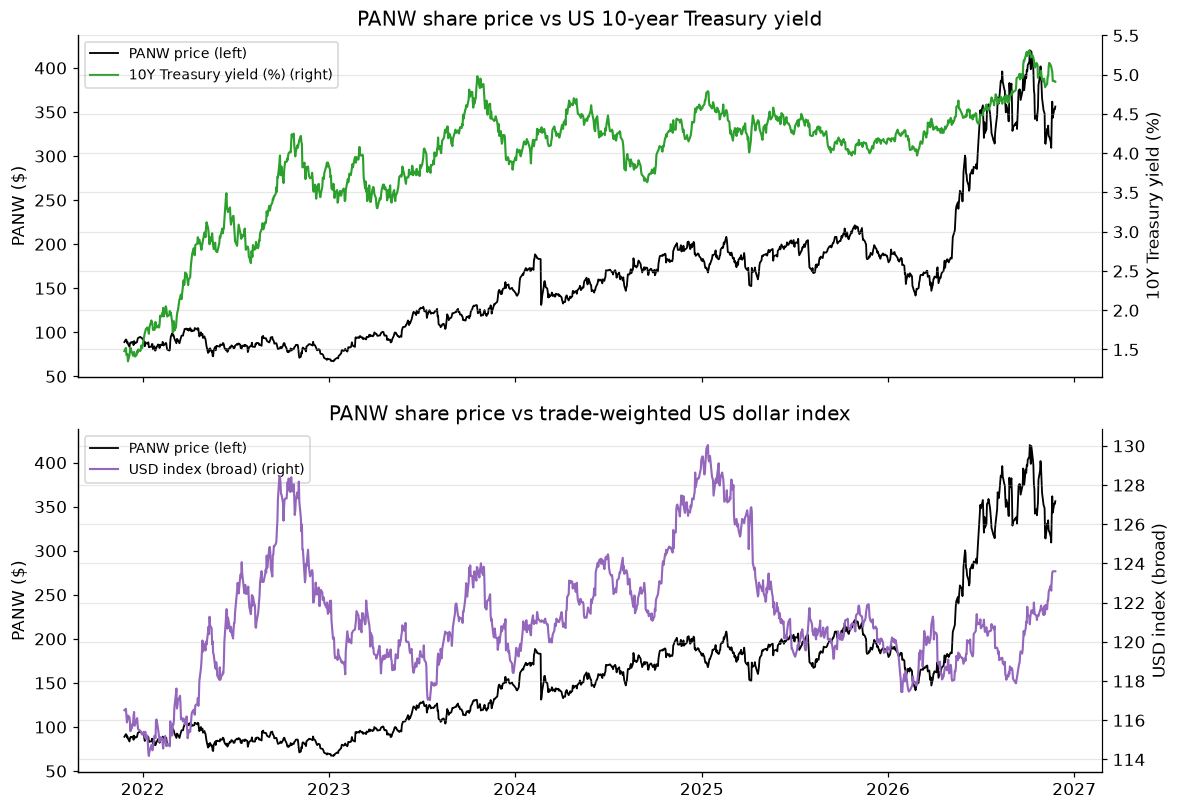

In [84]:
# ==== 4d. PANW vs interest rates and the dollar ====
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True)
for ax, col, color in [(a1, "10Y Treasury yield (%)", "tab:green"), (a2, "USD index (broad)", "tab:purple")]:
    ax.plot(prices.index, prices[TARGET], color="black", linewidth=1.2, label="PANW price (left)")
    ax.set_ylabel("PANW ($)")
    ax.grid(False)
    ax2 = ax.twinx()
    ax2.plot(macro.index, macro[col], color=color, linewidth=1.4, label=f"{col} (right)")
    ax2.set_ylabel(col)
    ax2.spines["right"].set_visible(True)
    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=9)
a1.set_title("PANW share price vs US 10-year Treasury yield")
a2.set_title("PANW share price vs trade-weighted US dollar index")
fig.tight_layout()
save(fig, "12_macro_rates_dollar")
plt.show()

In [85]:
# ==== 4e. Multi-factor regression: market, interest rates and the dollar (weekly, 5 years) ====
from math import erfc, sqrt

wk_px = prices.resample("W-FRI").last()
wk_macro = macro.resample("W-FRI").last()
reg = pd.DataFrame({
    "PANW excess return": wk_px[TARGET].pct_change() - RISK_FREE / 52,
    "Market excess return": wk_px[MARKET].pct_change() - RISK_FREE / 52,
    "Change in 10Y yield (pp)": wk_macro["10Y Treasury yield (%)"].diff(),
    "USD index return": wk_macro["USD index (broad)"].pct_change(),
}).dropna()

y = reg["PANW excess return"].values
X = np.column_stack([np.ones(len(reg)), reg.drop(columns="PANW excess return").values])
coef, *_ = np.linalg.lstsq(X, y, rcond=None)
resid = y - X @ coef
dof = len(y) - X.shape[1]
se = np.sqrt(np.diag(resid @ resid / dof * np.linalg.inv(X.T @ X)))
t_stats = coef / se
r2 = 1 - (resid @ resid) / ((y - y.mean()) @ (y - y.mean()))

factor_table = pd.DataFrame({
    "Coefficient": coef,
    "Std. error": se,
    "t-stat": t_stats,
    "p-value": [erfc(abs(t) / sqrt(2)) for t in t_stats],   # normal approximation (n > 200)
}, index=["Alpha (weekly)", "Market beta", "Rate sensitivity (per 1pp)", "USD sensitivity"])
factor_table.to_csv("tables/factor_regression.csv")

print(f"Weekly observations: {len(y)} | R-squared: {r2:.2f}")
print(f"Annualised alpha: {coef[0] * 52:.1%}")
print(f"A +0.25 percentage point weekly rise in the 10Y yield is associated with a {coef[2] * 0.25:+.2%} PANW excess return,")
print(f"and a +1% move in the dollar index with a {coef[3] / 100:+.2%} return, holding the market constant.")
show(factor_table, dec2=["Coefficient", "Std. error", "t-stat", "p-value"])

Weekly observations: 261 | R-squared: 0.22
Annualised alpha: 23.4%
A +0.25 percentage point weekly rise in the 10Y yield is associated with a +0.03% PANW excess return,
and a +1% move in the dollar index with a +1.15% return, holding the market constant.


,Coefficient,Std. error,t-stat,p-value
Alpha (weekly),0.00,0.00,1.35,0.18
Market beta,1.31,0.16,8.24,0.00
Rate sensitivity (per 1pp),0.00,0.03,0.05,0.96
USD sensitivity,1.15,0.58,2.00,0.05


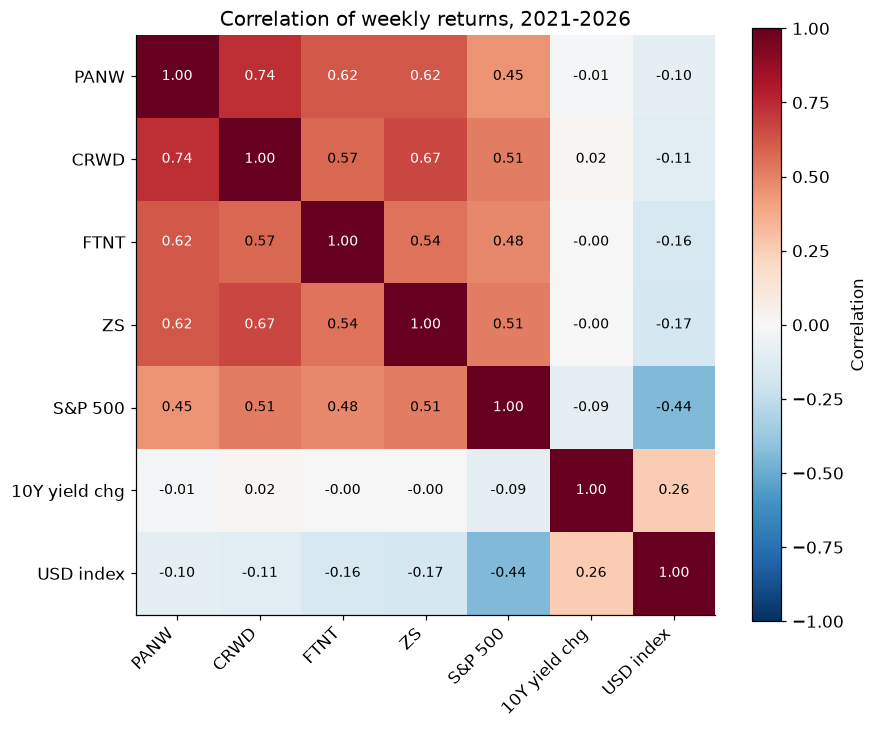

In [86]:
# ==== 4f. Correlation matrix of weekly returns (stocks, market and macro factors) ====
corr_data = pd.concat([
    wk_px.pct_change().rename(columns=lambda t: t.replace("^GSPC", "S&P 500")),
    reg[["Change in 10Y yield (pp)", "USD index return"]].rename(
        columns={"Change in 10Y yield (pp)": "10Y yield chg", "USD index return": "USD index"}),
], axis=1).dropna()
corr = corr_data.corr()
corr.to_csv("tables/correlation_matrix.csv")

fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.index)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(corr.values[i, j]) > 0.6 else "black")
fig.colorbar(im, ax=ax, label="Correlation")
ax.set_title("Correlation of weekly returns, 2021-2026")
save(fig, "13_correlation_matrix")
plt.show()

In [87]:
# ==== 5. Valuation multiples & analyst targets (Yahoo Finance snapshot) ====
FIELDS = {
    "currentPrice": "Price",
    "marketCap": "Market cap ($bn)",
    "trailingPE": "Trailing P/E",
    "forwardPE": "Forward P/E",
    "trailingEps": "Trailing EPS",
    "forwardEps": "Forward EPS",
    "priceToSalesTrailing12Months": "P/S (TTM)",
    "revenueGrowth": "Revenue growth (YoY)",
    "grossMargins": "Gross margin",
    "operatingMargins": "Operating margin",
    "targetLowPrice": "Analyst target low",
    "targetMeanPrice": "Analyst target mean",
    "targetHighPrice": "Analyst target high",
    "numberOfAnalystOpinions": "No. of analysts",
}

SNAPSHOT_FILE = "data/valuation_snapshot.csv"

if REFRESH_DATA or not os.path.exists(SNAPSHOT_FILE):
    rows = {}
    for t in [TARGET] + PEERS:
        info = yf.Ticker(t).info
        rows[LABELS[t]] = {label: info.get(key) for key, label in FIELDS.items()}
    fund = pd.DataFrame(rows).T.apply(pd.to_numeric, errors="coerce")
    fund["Market cap ($bn)"] = fund["Market cap ($bn)"] / 1e9
    fund.to_csv(SNAPSHOT_FILE)
    print("Downloaded fresh valuation data from Yahoo Finance and saved snapshot.")
else:
    fund = pd.read_csv(SNAPSHOT_FILE, index_col=0)
    print("Loaded saved valuation snapshot (set REFRESH_DATA = True to re-download).")

fund.to_csv("tables/valuation_snapshot.csv")

show(fund,
     money=["Price", "Trailing EPS", "Forward EPS", "Analyst target low",
            "Analyst target mean", "Analyst target high"],
     dec1=["Market cap ($bn)", "Trailing P/E", "Forward P/E", "P/S (TTM)"],
     pct=["Revenue growth (YoY)", "Gross margin", "Operating margin"])

Loaded saved valuation snapshot (set REFRESH_DATA = True to re-download).


,Price,Market cap ($bn),Trailing P/E,Forward P/E,Trailing EPS,Forward EPS,P/S (TTM),Revenue growth (YoY),Gross margin,Operating margin,Analyst target low,Analyst target mean,Analyst target high,No. of analysts
Palo Alto Networks,$356.14,292.4,624.8,72.4,$0.57,$4.92,23.5,39.2%,69.0%,4.9%,$190.00,$412.12,$510.00,51.0
CrowdStrike,$209.30,215.7,1744.2,126.5,$0.12,$1.65,37.5,28.3%,75.4%,-1.3%,$174.00,$249.42,$320.00,48.0
Fortinet,$134.96,99.2,44.1,34.6,$3.06,$3.90,12.6,20.5%,79.8%,32.9%,$110.00,$144.68,$190.00,37.0
Zscaler,$230.86,37.9,n/a,40.6,$-0.49,$5.68,10.8,20.5%,77.0%,-3.1%,$170.00,$256.83,$340.00,40.0


**Note:** Yahoo's *Forward EPS* is the analyst consensus for the next fiscal year (PANW's fiscal year ends 31 July) and is mostly
**non-GAAP** (excludes stock-based compensation), so it is much higher than GAAP EPS. Cross-check it with Refinitiv/Bloomberg
and state which one you use in the report.

## Fundamental analysis
Annual income statement, balance sheet and cash flow statement for PANW and peers (last 4 fiscal years, Yahoo Finance).
Note that fiscal years differ: PANW and Zscaler end in July, CrowdStrike in January, Fortinet in December.
All ratios use GAAP figures from the statements.

In [88]:
# ==== 5b. Download / load financial statements ====
def get_statements(ticker):
    """Annual income statement, balance sheet and cash flow (cached in data/)."""
    out = {}
    for name, attr in [("income", "income_stmt"), ("balance", "balance_sheet"), ("cashflow", "cashflow")]:
        path = f"data/{ticker}_{name}.csv"
        if REFRESH_DATA or not os.path.exists(path):
            df = getattr(yf.Ticker(ticker), attr)
            df.to_csv(path)
        else:
            df = pd.read_csv(path, index_col=0)
        df.columns = pd.to_datetime(df.columns)
        out[name] = df
    return out

def line(df, names, cols):
    """First matching row of a statement, aligned to the given fiscal-year columns."""
    for n in names:
        if n in df.index:
            return pd.to_numeric(df.loc[n], errors="coerce").reindex(cols)
    return pd.Series(np.nan, index=cols)

def compute_ratios(st):
    """Key profitability, efficiency and balance-sheet ratios per fiscal year."""
    inc, bs, cf = st["income"], st["balance"], st["cashflow"]
    cols = inc.columns[pd.notna(line(inc, ["Total Revenue"], inc.columns)).values]
    rev = line(inc, ["Total Revenue"], cols)
    equity = line(bs, ["Stockholders Equity", "Common Stock Equity"], cols)
    fcf = line(cf, ["Free Cash Flow"], cols)
    sbc = line(cf, ["Stock Based Compensation"], cols)
    r = pd.DataFrame({
        "Revenue ($bn)": rev / 1e9,
        "Gross margin": line(inc, ["Gross Profit"], cols) / rev,
        "Operating margin": line(inc, ["Operating Income"], cols) / rev,
        "Net margin": line(inc, ["Net Income", "Net Income Common Stockholders"], cols) / rev,
        "FCF ($bn)": fcf / 1e9,
        "FCF margin": fcf / rev,
        "SBC % of revenue": sbc / rev,
        "R&D % of revenue": line(inc, ["Research And Development"], cols) / rev,
        "ROE": line(inc, ["Net Income", "Net Income Common Stockholders"], cols) / equity,
        "ROA": line(inc, ["Net Income", "Net Income Common Stockholders"], cols) / line(bs, ["Total Assets"], cols),
        "Debt / equity": line(bs, ["Total Debt"], cols) / equity,
        "Current ratio": line(bs, ["Current Assets"], cols) / line(bs, ["Current Liabilities"], cols),
    }).sort_index()
    r.insert(1, "Revenue growth", r["Revenue ($bn)"].pct_change())
    r["Rule of 40"] = r["Revenue growth"] + r["FCF margin"]   # SaaS benchmark: growth + FCF margin >= 40%
    r.index = r.index.strftime("FY %b %Y")
    return r

statements = {t: get_statements(t) for t in [TARGET] + PEERS}
ratios = {LABELS[t]: compute_ratios(statements[t]) for t in [TARGET] + PEERS}
print("Statements loaded for:", ", ".join(ratios))

Statements loaded for: Palo Alto Networks, CrowdStrike, Fortinet, Zscaler


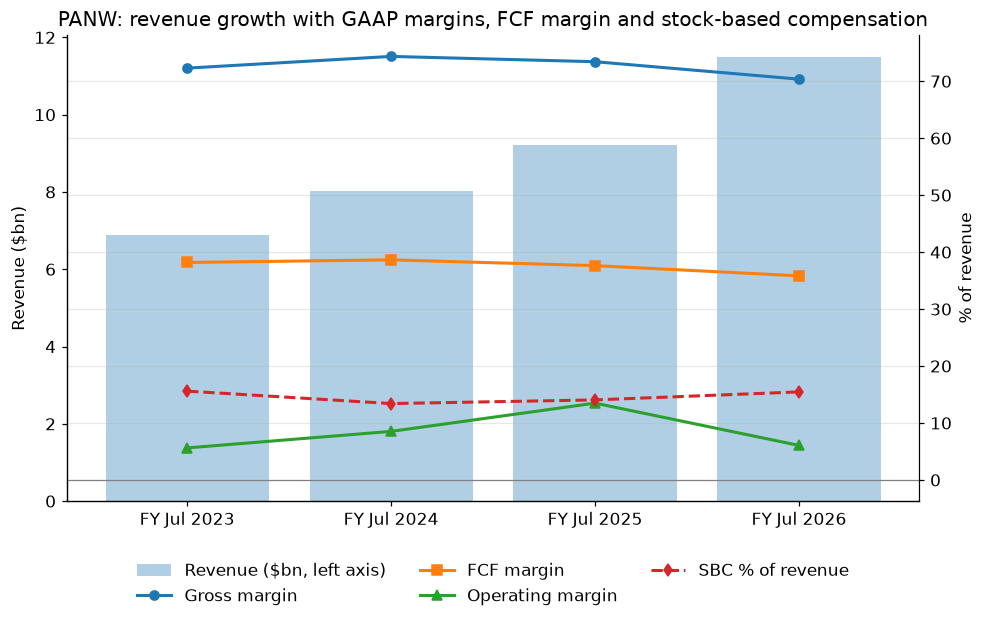

,FY Jul 2023,FY Jul 2024,FY Jul 2025,FY Jul 2026
Revenue ($bn),6.89,8.03,9.22,11.48
Revenue growth,n/a,16.5%,14.9%,24.5%
Gross margin,72.3%,74.3%,73.4%,70.4%
Operating margin,5.6%,8.5%,13.5%,6.1%
Net margin,6.4%,32.1%,12.3%,2.7%
FCF ($bn),2.63,3.10,3.47,4.11
FCF margin,38.2%,38.6%,37.6%,35.8%
SBC % of revenue,15.6%,13.4%,14.0%,15.5%
R&D % of revenue,23.3%,22.5%,21.5%,22.2%
ROE,25.1%,49.9%,14.5%,1.1%


In [89]:
# ==== 5c. PANW fundamentals over time ====
PCT_COLS = ["Revenue growth", "Gross margin", "Operating margin", "Net margin", "FCF margin",
            "SBC % of revenue", "R&D % of revenue", "ROE", "ROA", "Rule of 40"]
DEC_COLS = ["Revenue ($bn)", "FCF ($bn)", "Debt / equity", "Current ratio"]

panw_fund = ratios[LABELS[TARGET]]
panw_fund.to_csv("tables/panw_fundamentals.csv")

fig, ax1 = plt.subplots()
x = np.arange(len(panw_fund))
ax1.bar(x, panw_fund["Revenue ($bn)"], color="tab:blue", alpha=0.35, label="Revenue ($bn, left axis)")
ax1.set_ylabel("Revenue ($bn)")
ax1.set_xticks(x)
ax1.set_xticklabels(panw_fund.index)
ax1.grid(False)
ax2 = ax1.twinx()
for col, style in [("Gross margin", "o-"), ("FCF margin", "s-"), ("Operating margin", "^-"), ("SBC % of revenue", "d--")]:
    ax2.plot(x, panw_fund[col] * 100, style, linewidth=2, label=col)
ax2.axhline(0, color="grey", linewidth=0.8)
ax2.set_ylabel("% of revenue")
ax2.spines["right"].set_visible(True)
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
ax1.set_title("PANW: revenue growth with GAAP margins, FCF margin and stock-based compensation")
save(fig, "07_panw_fundamentals")
plt.show()

show(panw_fund, pct=PCT_COLS, dec2=DEC_COLS).T

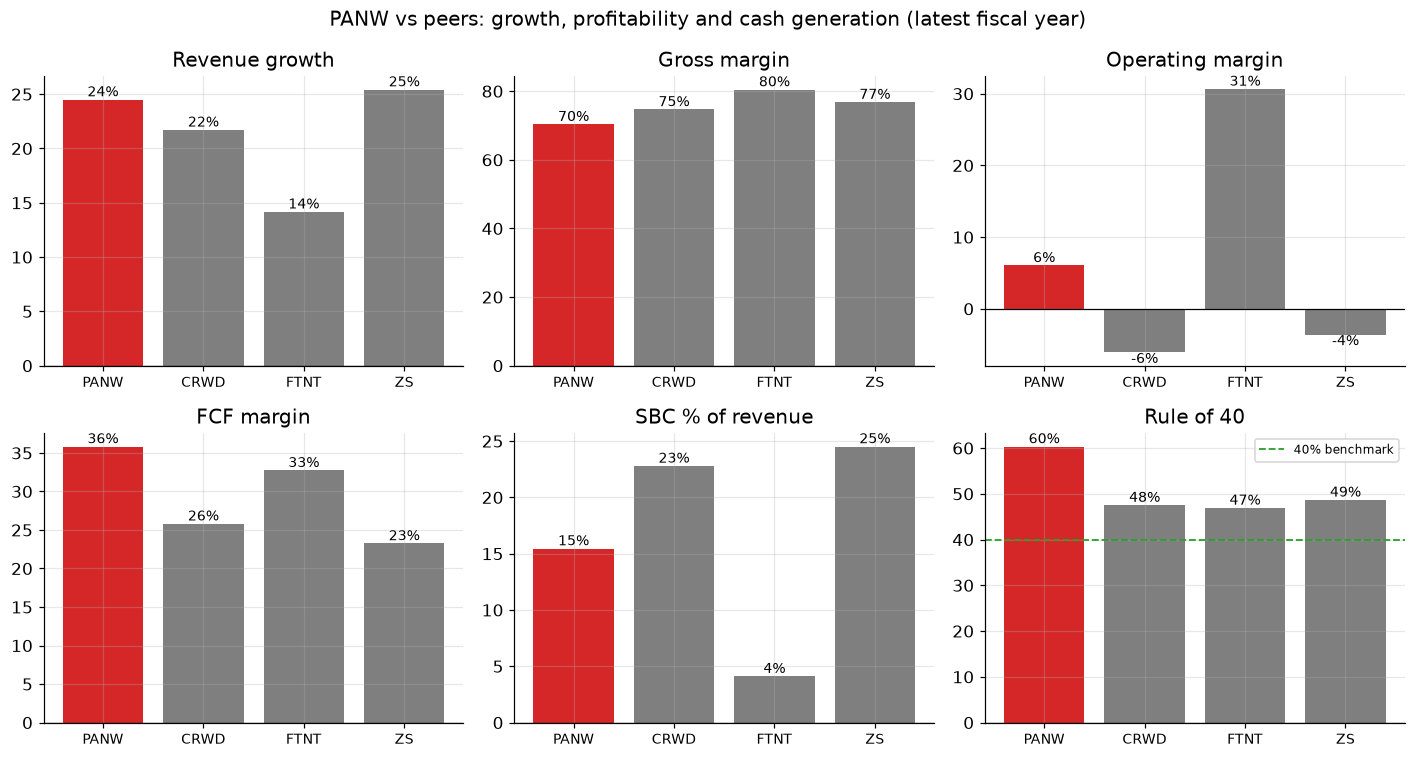

,Palo Alto Networks,CrowdStrike,Fortinet,Zscaler
Fiscal year,FY Jul 2026,FY Jan 2026,FY Dec 2025,FY Jul 2026
Revenue ($bn),11.48,4.81,6.80,3.35
Revenue growth,24.5%,21.7%,14.2%,25.4%
Gross margin,70.4%,74.7%,80.5%,76.8%
Operating margin,6.1%,-6.1%,30.7%,-3.6%
Net margin,2.7%,-3.4%,27.3%,-1.9%
FCF ($bn),4.11,1.24,2.23,0.78
FCF margin,35.8%,25.8%,32.7%,23.2%
SBC % of revenue,15.5%,22.8%,4.1%,24.5%
R&D % of revenue,22.2%,28.8%,12.0%,26.9%


In [90]:
# ==== 5d. Peer comparison (latest fiscal year) ====
latest = pd.DataFrame({name: r.iloc[-1] for name, r in ratios.items()}).T
latest.insert(0, "Fiscal year", [r.index[-1] for r in ratios.values()])
latest.to_csv("tables/peer_fundamentals.csv")

panels = ["Revenue growth", "Gross margin", "Operating margin", "FCF margin", "SBC % of revenue", "Rule of 40"]
colors = ["tab:red" if n == LABELS[TARGET] else "tab:grey" for n in latest.index]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.flat, panels):
    vals = latest[col].astype(float) * 100
    ax.bar(range(len(vals)), vals, color=colors)
    ax.set_xticks(range(len(vals)))
    ax.set_xticklabels([TARGET] + PEERS, fontsize=9)
    ax.axhline(0, color="black", linewidth=0.8)
    if col == "Rule of 40":
        ax.axhline(40, color="tab:green", linestyle="--", linewidth=1.2, label="40% benchmark")
        ax.legend(fontsize=8)
    for i, val in enumerate(vals):
        if pd.notna(val):
            ax.text(i, val, f"{val:.0f}%", ha="center", va="bottom" if val >= 0 else "top", fontsize=9)
    ax.set_title(col)
fig.suptitle("PANW vs peers: growth, profitability and cash generation (latest fiscal year)", fontsize=13)
fig.tight_layout()
save(fig, "08_peer_fundamentals")
plt.show()

show(latest, pct=PCT_COLS, dec2=DEC_COLS).T

In [91]:
# ==== 6. Monte Carlo simulation (Geometric Brownian Motion), 1-year horizon ====
N_SIMS = 10_000
HORIZON = 252            # trading days in one year
VOL_WINDOW_YEARS = 2     # volatility estimated from the last 2 years

S0 = prices[TARGET].iloc[-1]
log_ret = np.log(prices[TARGET]).diff().dropna()
recent = log_ret[log_ret.index >= log_ret.index[-1] - pd.DateOffset(years=VOL_WINDOW_YEARS)]
sigma = recent.std() * np.sqrt(252)

# Drift = CAPM expected return (not the historical return, which would simply extrapolate the past rally)
mu = metrics.loc[LABELS[TARGET], "CAPM expected return"]

rng = np.random.default_rng(SEED)
dt = 1 / 252
Z = rng.standard_normal((HORIZON, N_SIMS))
steps = (mu - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z
paths = S0 * np.exp(np.vstack([np.zeros(N_SIMS), steps.cumsum(axis=0)]))
terminal = paths[-1]

q = np.percentile(paths, [5, 25, 50, 75, 95], axis=1)
mc = pd.Series({
    "Current price": S0,
    "Drift (mu)": mu,
    "Volatility (sigma)": sigma,
    "5th percentile": np.percentile(terminal, 5),
    "25th percentile": np.percentile(terminal, 25),
    "Median": np.median(terminal),
    "Mean": terminal.mean(),
    "75th percentile": np.percentile(terminal, 75),
    "95th percentile": np.percentile(terminal, 95),
    "P(price higher in 1y)": (terminal > S0).mean(),
})
mc.to_csv("tables/monte_carlo_summary.csv")
print(mc.to_string(float_format=lambda v: f"{v:,.3f}"))

Current price           356.140
Drift (mu)                0.093
Volatility (sigma)        0.446
5th percentile          168.823
25th percentile         263.370
Median                  354.333
Mean                    392.483
75th percentile         480.882
95th percentile         741.170
P(price higher in 1y)     0.496


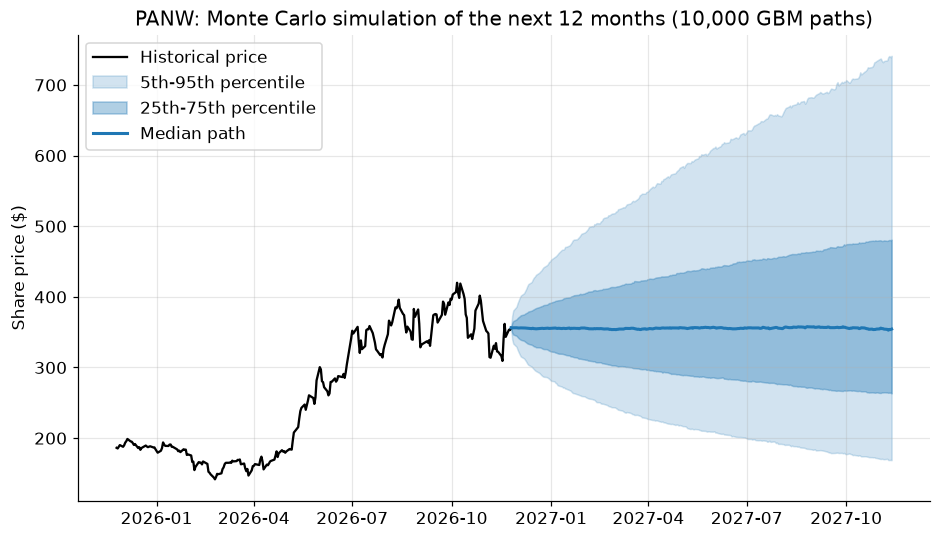

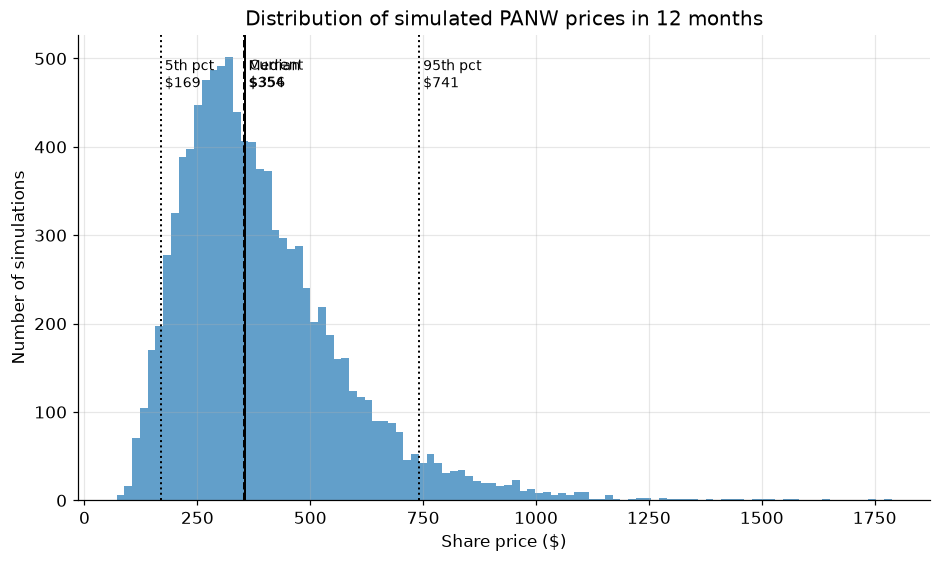

In [92]:
# ==== 7. Monte Carlo figures: fan chart + distribution of 1-year prices ====
future_dates = pd.bdate_range(prices.index[-1], periods=HORIZON + 1)
history = prices[TARGET].iloc[-252:]

fig, ax = plt.subplots()
ax.plot(history.index, history, color="black", linewidth=1.5, label="Historical price")
ax.fill_between(future_dates, q[0], q[4], alpha=0.2, color="tab:blue", label="5th-95th percentile")
ax.fill_between(future_dates, q[1], q[3], alpha=0.35, color="tab:blue", label="25th-75th percentile")
ax.plot(future_dates, q[2], color="tab:blue", linewidth=2, label="Median path")
ax.set_title(f"PANW: Monte Carlo simulation of the next 12 months ({N_SIMS:,} GBM paths)")
ax.set_ylabel("Share price ($)")
ax.legend(loc="upper left")
save(fig, "02_monte_carlo_fan")
plt.show()

fig, ax = plt.subplots()
ax.hist(terminal, bins=100, color="tab:blue", alpha=0.7)
for value, label, style in [(S0, "Current", "-"), (mc["Median"], "Median", "--"),
                            (mc["5th percentile"], "5th pct", ":"), (mc["95th percentile"], "95th pct", ":")]:
    ax.axvline(value, color="black", linestyle=style, linewidth=1.3)
    ax.text(value, ax.get_ylim()[1] * 0.95, f" {label}\n ${value:,.0f}", fontsize=9, va="top")
ax.set_title("Distribution of simulated PANW prices in 12 months")
ax.set_xlabel("Share price ($)")
ax.set_ylabel("Number of simulations")
save(fig, "03_monte_carlo_distribution")
plt.show()

In [93]:
# ==== 7b. Value at Risk (VaR) and Expected Shortfall (CVaR) ====
# VaR  = the loss that will not be exceeded with the given confidence
# CVaR = the average loss in the worst cases beyond the VaR (expected shortfall)
ret_1y = terminal / S0 - 1
daily_ret = prices[TARGET].pct_change().dropna()

risk = {}
for cl in [0.95, 0.99]:
    var_1y = -np.percentile(ret_1y, (1 - cl) * 100)
    var_1d = -np.percentile(daily_ret, (1 - cl) * 100)
    risk[f"{cl:.0%} confidence"] = {
        "1-day VaR (historical)": var_1d,
        "1-day CVaR (historical)": -daily_ret[daily_ret <= -var_1d].mean(),
        "1-year VaR (Monte Carlo)": var_1y,
        "1-year CVaR (Monte Carlo)": -ret_1y[ret_1y <= -var_1y].mean(),
    }
var_table = pd.DataFrame(risk)
var_table.to_csv("tables/value_at_risk.csv")

v95 = var_table.loc["1-year VaR (Monte Carlo)", "95% confidence"]
print(f"With 95% confidence, a $10,000 PANW position should not lose more than ${10_000 * v95:,.0f} over one year "
      f"(but in the worst 5% of cases the average loss is "
      f"${10_000 * var_table.loc['1-year CVaR (Monte Carlo)', '95% confidence']:,.0f}).")
show(var_table, pct=list(var_table.columns))

With 95% confidence, a $10,000 PANW position should not lose more than $5,260 over one year (but in the worst 5% of cases the average loss is $6,016).


,95% confidence,99% confidence
1-day VaR (historical),4.0%,7.0%
1-day CVaR (historical),6.0%,9.5%
1-year VaR (Monte Carlo),52.6%,65.2%
1-year CVaR (Monte Carlo),60.2%,68.9%


## Scenario valuation (forward P/E)
Price in 12 months = (Forward EPS × (1 + EPS growth)) × Forward P/E.
In a year's time the market will price PANW on the *following* year's earnings, hence the growth step.

⚠️ **The numbers in the `scenarios` table below are placeholders.** Replace them with assumptions you can justify
(analyst EPS consensus from Refinitiv/Bloomberg, Sean's fundamental figures, peer multiples) and cite the source in the report.

In [94]:
# ==== 8. Bear / Base / Bull scenarios ====
# EPS anchor: FY2027 non-GAAP EPS guidance midpoint ($4.26-$4.30), Q1 FY27 earnings release, 18 Nov 2026
EPS_FY27 = 4.28
ntm_pe_now = S0 / EPS_FY27
fy28_consensus = fund.loc[LABELS[TARGET], "Forward EPS"]   # Yahoo "Forward EPS" = FY2028 analyst consensus
peer_fwd_pe = fund.loc[[LABELS[p] for p in PEERS], "Forward P/E"].median()

print(f"Current price: ${S0:,.2f}")
print(f"P/E on FY27 guidance (current next-twelve-months multiple): {ntm_pe_now:.1f}x")
print(f"FY28 consensus EPS: ${fy28_consensus:.2f} -> implied growth vs FY27: {fy28_consensus / EPS_FY27 - 1:.1%}")
print(f"Peer median forward P/E: {peer_fwd_pe:.1f}x")

# In 12 months the market will price PANW on FY2028 earnings (the next twelve months at that point),
# so: target price = FY27 EPS x (1 + FY28 growth) x P/E
scenarios = pd.DataFrame({
    "EPS growth":  [0.08, 0.15, 0.22],   # base 15% ~= FY28 analyst consensus
    "Forward P/E": [60.0, 80.0, 90.0],   # bear: de-rating, base: mild compression, bull: premium expands
    "Probability": [0.25, 0.50, 0.25],
}, index=["Bear", "Base", "Bull"])
assert abs(scenarios["Probability"].sum() - 1) < 1e-9, "Probabilities must add up to 1"

scenarios["EPS in 12m"] = EPS_FY27 * (1 + scenarios["EPS growth"])
scenarios["Target price"] = scenarios["EPS in 12m"] * scenarios["Forward P/E"]
scenarios["Implied return"] = scenarios["Target price"] / S0 - 1

weighted_target = (scenarios["Target price"] * scenarios["Probability"]).sum()
scenarios.to_csv("tables/scenarios.csv")

print(f"\nProbability-weighted target: ${weighted_target:,.2f} ({weighted_target / S0 - 1:+.1%} vs ${S0:,.2f} today)")
show(scenarios, pct=["EPS growth", "Probability", "Implied return"],
     dec1=["Forward P/E"], money=["EPS in 12m", "Target price"])

Current price: $356.14
P/E on FY27 guidance (current next-twelve-months multiple): 83.2x
FY28 consensus EPS: $4.92 -> implied growth vs FY27: 15.0%
Peer median forward P/E: 40.6x

Probability-weighted target: $383.70 (+7.7% vs $356.14 today)


,EPS growth,Forward P/E,Probability,EPS in 12m,Target price,Implied return
Bear,8.0%,60.0,25.0%,$4.62,$277.34,-22.1%
Base,15.0%,80.0,50.0%,$4.92,$393.76,10.6%
Bull,22.0%,90.0,25.0%,$5.22,$469.94,32.0%


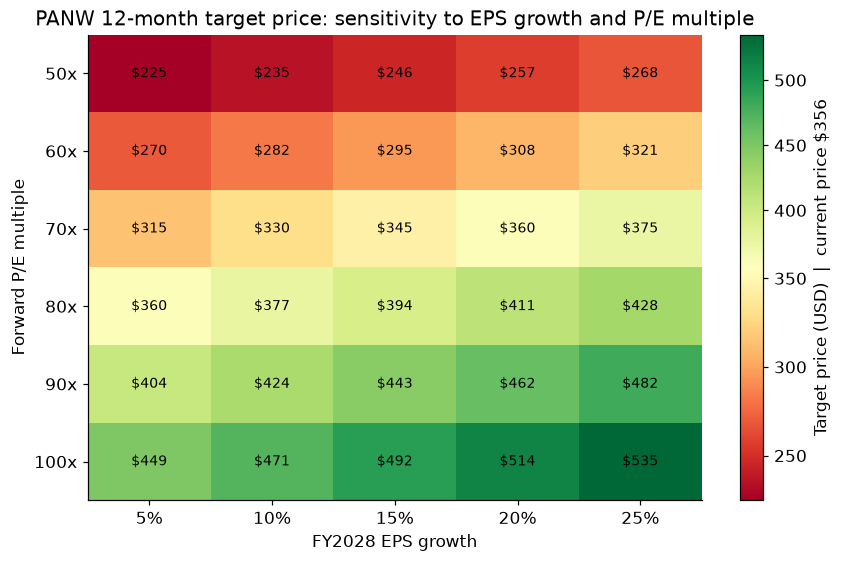

In [95]:
# ==== 8b. Sensitivity of the P/E target price to the two key assumptions ====
from matplotlib.colors import TwoSlopeNorm

def heatmap(df, title, xlabel, ylabel, name):
    """Heatmap of target prices: green = above today's price, red = below."""
    vals = df.values.astype(float)
    norm = TwoSlopeNorm(vcenter=S0, vmin=min(np.nanmin(vals), S0 * 0.99), vmax=max(np.nanmax(vals), S0 * 1.01))
    fig, ax = plt.subplots(figsize=(9, 5.5))
    im = ax.imshow(vals, cmap="RdYlGn", norm=norm, aspect="auto")
    ax.set_xticks(range(df.shape[1]))
    ax.set_xticklabels(df.columns)
    ax.set_yticks(range(df.shape[0]))
    ax.set_yticklabels(df.index)
    ax.grid(False)
    for i in range(df.shape[0]):
        for j in range(df.shape[1]):
            ax.text(j, i, f"${vals[i, j]:,.0f}", ha="center", va="center", fontsize=9)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    fig.colorbar(im, ax=ax, label=f"Target price (USD)  |  current price \\${S0:,.0f}")
    save(fig, name)
    plt.show()

growth_grid = [0.05, 0.10, 0.15, 0.20, 0.25]
pe_grid = [50, 60, 70, 80, 90, 100]
pe_sens = pd.DataFrame(
    [[EPS_FY27 * (1 + g) * pe for g in growth_grid] for pe in pe_grid],
    index=[f"{pe}x" for pe in pe_grid], columns=[f"{g:.0%}" for g in growth_grid])
pe_sens.to_csv("tables/pe_sensitivity.csv")

heatmap(pe_sens, "PANW 12-month target price: sensitivity to EPS growth and P/E multiple",
        "FY2028 EPS growth", "Forward P/E multiple", "05_pe_sensitivity")

## Discounted cash flow (DCF) valuation
Two-stage free cash flow to the firm (FCFF) model: FCF grows at `G_HIGH` for 5 years, fades linearly to `G_TERMINAL` over years 6-10,
then a Gordon-growth terminal value. Cash flows are discounted at the WACC (cost of equity from CAPM).
A **reverse DCF** then solves for the 5-year growth rate the market is implicitly pricing in.

⚠️ `G_HIGH`, `G_TERMINAL` and the cost-of-debt spread are assumptions; justify them in the report.

In [96]:
# ==== 9. DCF inputs: latest annual cash flow statement & balance sheet ====
DCF_FILE = "data/dcf_inputs.csv"

def pick(statement, names):
    """Most recent value of the first matching row in a yfinance statement (columns are newest first)."""
    for n in names:
        if n in statement.index:
            s = statement.loc[n].dropna()
            if len(s):
                return float(s.iloc[0])
    return np.nan

if REFRESH_DATA or not os.path.exists(DCF_FILE):
    tk = yf.Ticker(TARGET)
    cf, bs = tk.cashflow, tk.balance_sheet
    dcf_inputs = pd.Series({
        "Fiscal year end": str(pd.Timestamp(cf.columns[0]).date()),
        "Operating cash flow": pick(cf, ["Operating Cash Flow"]),
        "Capital expenditure": pick(cf, ["Capital Expenditure"]),
        "Free cash flow": pick(cf, ["Free Cash Flow"]),
        "Stock-based compensation": pick(cf, ["Stock Based Compensation"]),
        "Total debt": pick(bs, ["Total Debt"]),
        "Cash & short-term investments": pick(bs, ["Cash Cash Equivalents And Short Term Investments",
                                                   "Cash And Cash Equivalents"]),
    })
    dcf_inputs.to_csv(DCF_FILE, header=["value"])
    print("Downloaded statements from Yahoo Finance and saved snapshot.")
else:
    dcf_inputs = pd.read_csv(DCF_FILE, index_col=0)["value"]
    print("Loaded saved DCF inputs (set REFRESH_DATA = True to re-download).")

# If any value below shows as nan, type it in manually from PANW's 10-K (in dollars), e.g.:
# dcf_inputs["Free cash flow"] = 4.0e9

v = pd.to_numeric(dcf_inputs, errors="coerce")
print(f"Fiscal year ended: {dcf_inputs['Fiscal year end']}")
print((v.drop("Fiscal year end") / 1e9).to_string(float_format=lambda x: f"${x:,.2f}bn"))

Loaded saved DCF inputs (set REFRESH_DATA = True to re-download).
Fiscal year ended: 2026-07-31
Operating cash flow              $4.55bn
Capital expenditure             $-0.44bn
Free cash flow                   $4.11bn
Stock-based compensation         $1.77bn
Total debt                       $2.50bn
Cash & short-term investments    $3.07bn


In [97]:
# ==== 10. DCF valuation + reverse DCF ====
# ---- ASSUMPTIONS: edit these ----
G_HIGH = 0.20               # FCF growth, years 1-5
G_TERMINAL = 0.03           # perpetual growth after year 10 (~ long-run nominal GDP growth)
COST_OF_DEBT_SPREAD = 0.01  # credit spread over the risk-free rate
TAX_RATE = 0.21             # US federal corporate tax rate
# ---------------------------------

FCF0 = v["Free cash flow"]
SBC = v["Stock-based compensation"]
DEBT = v["Total debt"] if pd.notna(v["Total debt"]) else 0.0
CASH = v["Cash & short-term investments"] if pd.notna(v["Cash & short-term investments"]) else 0.0
E = fund.loc[LABELS[TARGET], "Market cap ($bn)"] * 1e9
SHARES = E / fund.loc[LABELS[TARGET], "Price"]

cost_equity = metrics.loc[LABELS[TARGET], "CAPM expected return"]
cost_debt = (RISK_FREE + COST_OF_DEBT_SPREAD) * (1 - TAX_RATE)
WACC = E / (E + DEBT) * cost_equity + DEBT / (E + DEBT) * cost_debt

def growth_path(g_high, g_term, years=10, high_years=5):
    """g_high for the first 5 years, then a linear fade towards g_term over years 6-10."""
    fade = np.linspace(g_high, g_term, years - high_years + 2)[1:-1]
    return np.concatenate([np.full(high_years, g_high), fade])

def dcf_value(fcf0, g_high, g_term, wacc):
    """Intrinsic value per share from a two-stage DCF."""
    if wacc <= g_term:
        return np.nan, np.nan, np.nan
    fcf = fcf0 * np.cumprod(1 + growth_path(g_high, g_term))
    t = np.arange(1, len(fcf) + 1)
    pv_fcf = (fcf / (1 + wacc) ** t).sum()
    pv_tv = fcf[-1] * (1 + g_term) / (wacc - g_term) / (1 + wacc) ** t[-1]
    return (pv_fcf + pv_tv - DEBT + CASH) / SHARES, pv_fcf, pv_tv

dcf_price, pv_fcf, pv_tv = dcf_value(FCF0, G_HIGH, G_TERMINAL, WACC)
dcf_price_sbc = dcf_value(FCF0 - SBC, G_HIGH, G_TERMINAL, WACC)[0]

# Reverse DCF: find the 5-year growth rate that makes the DCF value equal today's price (bisection)
lo, hi = -0.5, 2.0
for _ in range(200):
    mid = (lo + hi) / 2
    lo, hi = (mid, hi) if dcf_value(FCF0, mid, G_TERMINAL, WACC)[0] < S0 else (lo, mid)
implied_growth = mid

projection = pd.DataFrame({
    "Year": np.arange(1, 11),
    "FCF growth": growth_path(G_HIGH, G_TERMINAL),
})
projection["FCF ($bn)"] = FCF0 * np.cumprod(1 + projection["FCF growth"]) / 1e9
projection["PV of FCF ($bn)"] = projection["FCF ($bn)"] / (1 + WACC) ** projection["Year"]
projection.to_csv("tables/dcf_projection.csv", index=False)

dcf_summary = pd.Series({
    "Cost of equity (CAPM)": cost_equity,
    "WACC": WACC,
    "PV of 10-year FCF ($bn)": pv_fcf / 1e9,
    "PV of terminal value ($bn)": pv_tv / 1e9,
    "Terminal value share of EV": pv_tv / (pv_fcf + pv_tv),
    "DCF value per share": dcf_price,
    "DCF value per share (FCF after SBC)": dcf_price_sbc,
    "Current price": S0,
    "Upside / downside": dcf_price / S0 - 1,
    "Implied 5-year FCF growth (reverse DCF)": implied_growth,
})
dcf_summary.to_csv("tables/dcf_summary.csv", header=["value"])
print(dcf_summary.to_string(float_format=lambda x: f"{x:,.3f}"))
show(projection.set_index("Year"), pct=["FCF growth"], dec2=["FCF ($bn)", "PV of FCF ($bn)"])

Cost of equity (CAPM)                       0.093
WACC                                        0.092
PV of 10-year FCF ($bn)                    64.295
PV of terminal value ($bn)                120.355
Terminal value share of EV                  0.652
DCF value per share                       225.605
DCF value per share (FCF after SBC)       128.598
Current price                             356.140
Upside / downside                          -0.367
Implied 5-year FCF growth (reverse DCF)     0.282


,FCF growth,FCF ($bn),PV of FCF ($bn)
Year,,,
1,20.0%,4.94,4.52
2,20.0%,5.92,4.96
3,20.0%,7.11,5.45
4,20.0%,8.53,5.99
5,20.0%,10.23,6.58
6,17.2%,11.99,7.06
7,14.3%,13.71,7.39
8,11.5%,15.29,7.55
9,8.7%,16.61,7.51


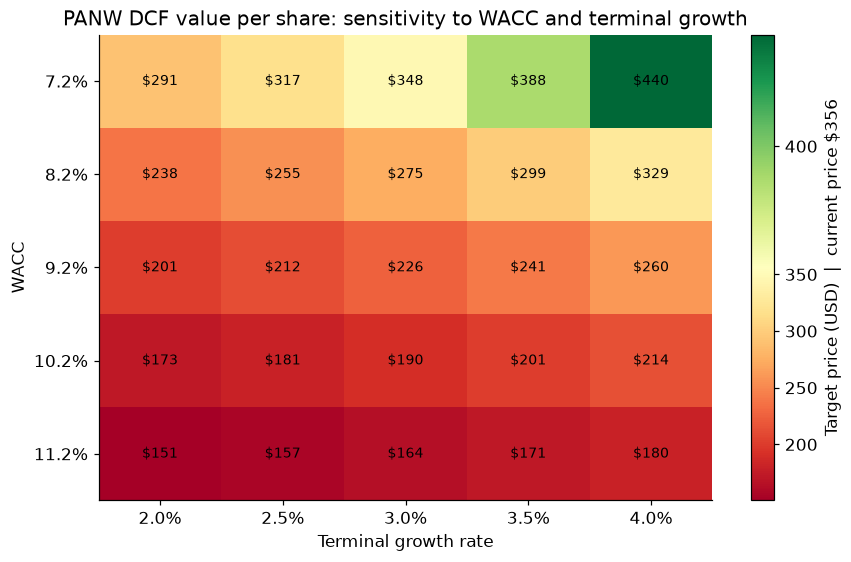

In [98]:
# ==== 11. DCF sensitivity: WACC vs terminal growth ====
wacc_grid = WACC + np.array([-0.02, -0.01, 0.0, 0.01, 0.02])
gterm_grid = [0.02, 0.025, 0.03, 0.035, 0.04]
dcf_sens = pd.DataFrame(
    [[dcf_value(FCF0, G_HIGH, g, w)[0] for g in gterm_grid] for w in wacc_grid],
    index=[f"{w:.1%}" for w in wacc_grid], columns=[f"{g:.1%}" for g in gterm_grid])
dcf_sens.to_csv("tables/dcf_sensitivity.csv")

heatmap(dcf_sens, "PANW DCF value per share: sensitivity to WACC and terminal growth",
        "Terminal growth rate", "WACC", "06_dcf_sensitivity")

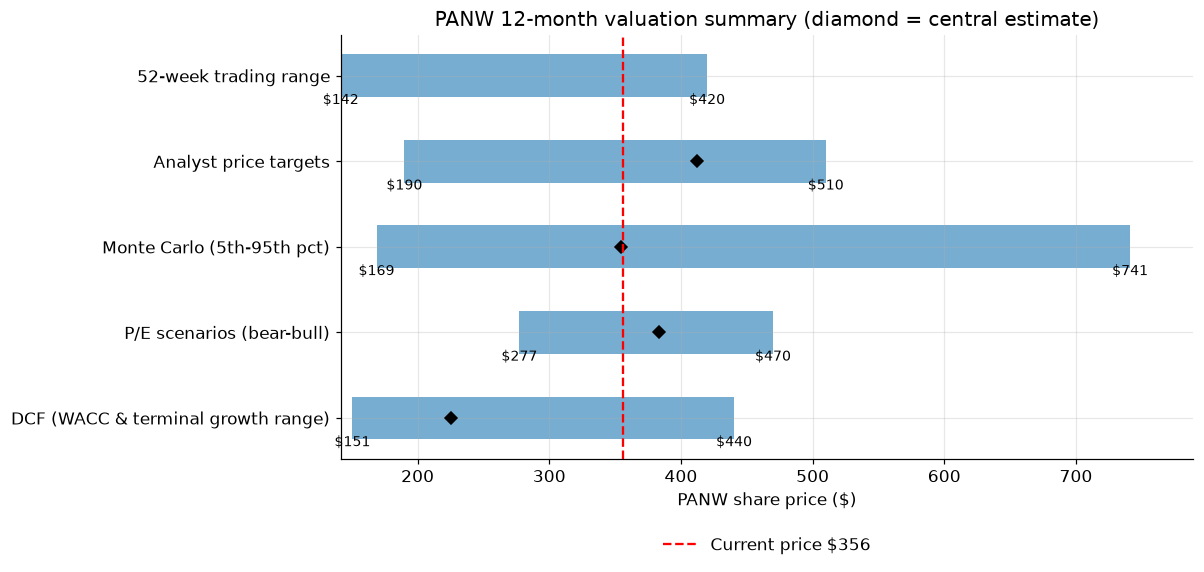

,Low,Mid,High
52-week trading range,$141.67,n/a,$419.91
Analyst price targets,$190.00,$412.12,$510.00
Monte Carlo (5th-95th pct),$168.82,$354.33,$741.17
P/E scenarios (bear-bull),$277.34,$383.70,$469.94
DCF (WACC & terminal growth range),$150.54,$225.60,$440.38


In [99]:
# ==== 12. Valuation summary ("football field" chart) ====
last_year = prices[TARGET].iloc[-252:]
ranges = pd.DataFrame({
    "Low":  [last_year.min(), fund.loc[LABELS[TARGET], "Analyst target low"],
             mc["5th percentile"], scenarios.loc["Bear", "Target price"], np.nanmin(dcf_sens.values)],
    "Mid":  [np.nan, fund.loc[LABELS[TARGET], "Analyst target mean"],
             mc["Median"], weighted_target, dcf_price],
    "High": [last_year.max(), fund.loc[LABELS[TARGET], "Analyst target high"],
             mc["95th percentile"], scenarios.loc["Bull", "Target price"], np.nanmax(dcf_sens.values)],
}, index=["52-week trading range", "Analyst price targets", "Monte Carlo (5th-95th pct)",
          "P/E scenarios (bear-bull)", "DCF (WACC & terminal growth range)"])
ranges.to_csv("tables/valuation_summary.csv")

fig, ax = plt.subplots(figsize=(10, 5))
for i, (name, r) in enumerate(ranges.iterrows()):
    ax.barh(i, r["High"] - r["Low"], left=r["Low"], height=0.5, color="tab:blue", alpha=0.6)
    if pd.notna(r["Mid"]):
        ax.plot(r["Mid"], i, marker="D", color="black")
    ax.text(r["Low"], i + 0.33, f"${r['Low']:,.0f}", ha="center", fontsize=9)
    ax.text(r["High"], i + 0.33, f"${r['High']:,.0f}", ha="center", fontsize=9)
ax.axvline(S0, color="red", linestyle="--", linewidth=1.5, label=f"Current price ${S0:,.0f}")
ax.set_yticks(range(len(ranges)))
ax.set_yticklabels(ranges.index)
ax.invert_yaxis()
ax.set_xlabel("PANW share price ($)")
ax.set_title("PANW 12-month valuation summary (diamond = central estimate)")
ax.margins(x=0.08)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), frameon=False)
save(fig, "04_valuation_summary")
plt.show()

show(ranges, money=["Low", "Mid", "High"])